# **Quiver Grassmannians in OSCAR**

include def of quiver grassmannians and citation

In [3]:
using Oscar

  ___   ___   ___    _    ____
 / _ \ / __\ / __\  / \  |  _ \  | Combining and extending ANTIC, GAP,
| |_| |\__ \| |__  / ^ \ |  ´ /  | Polymake and Singular
 \___/ \___/ \___//_/ \_\|_|\_\  | Type "?Oscar" for more information
o--------o-----o-----o--------o  | Documentation: https://docs.oscar-system.org
  S Y M B O L I C   T O O L S    | 1.9.0-DEV #master 1eeed51 2026-10-06


In [4]:
#checks that the dimensions of the input matrices match the dimension labels on vertices
function check_matrix_dimensions(quiver::Graph{Directed}, ambient_dims::Vector{Int}, input_matrices::AbstractVector{<:MatElem})
    for (e, A) in zip(edges(quiver), input_matrices)
        u = src(e)
        v = dst(e)

        @req nrows(A) == ambient_dims[u] begin
            "Matrix for edge $u → $v has $(nrows(A)) rows, " *
            "but the source vertex has dimension $(ambient_dims[u]). " *
            "Check input matrices satisfy OSCAR's freemodule morphism convention."
        end

        @req ncols(A) == ambient_dims[v] begin
            "Matrix for edge $u → $v has $(ncols(A)) columns, " *
            "but the target vertex has dimension $(ambient_dims[v]). " *
            "Check input matrices satisfy OSCAR's freemodule morphism convention."
        end
    end
end

check_matrix_dimensions (generic function with 1 method)

In [5]:
struct QuiverRepresentation{C <: FieldElem}
    quiver::Graph{Directed}
    ambient_dims::Vector{Int}
    vertex_vector_spaces::Vector{Generic.FreeModule{C}}
    edge_morphisms::Vector{Generic.ModuleHomomorphism{C}}
    base_field::Field # elem_type(C)
    function QuiverRepresentation(quiver::Graph{Directed}, ambient_dims::Vector{Int}, input_matrices::AbstractVector{<:MatElem}, base_field::Field)
        @req n_vertices(quiver) == length(ambient_dims) "each vertex needs an ambient dimension"
        @req n_edges(quiver) == length(input_matrices) "each edge needs a linear map"
        try
            input_matrices = change_base_ring.(Ref(base_field), input_matrices)
        catch
            error("The matrix entries cannot be coerced into the specified ring")
        end
        check_matrix_dimensions(quiver, ambient_dims, input_matrices)
        vertex_vector_spaces = [vector_space(base_field,ambient_dims[i]) for i in vertices(quiver)]
        new{elem_type(base_field)}(quiver, ambient_dims, vertex_vector_spaces, edge_morphisms(quiver, input_matrices, vertex_vector_spaces), base_field)
    end
end

#convert matrices to free module morphisms
function edge_morphisms(G::Graph{Directed}, As::AbstractVector{<:MatElem}, vertex_vector_spaces::Vector{Generic.FreeModule{C}}) where {C <: FieldElem}
    Vs = vertex_vector_spaces
    return [
        hom(Vs[src(e)],
            Vs[dst(e)],
            A)
        for (A, e) in zip(As, edges(G))
    ]
end
#print functions
function Base.show(io::IO, qR::QuiverRepresentation)
    print(io, "Quiver representation over ",qR.base_field," with ambient dimensions ",qR.ambient_dims, " and ",length(qR.edge_morphisms)," arrows")
end

In [6]:
function quiver_representation(quiver::Graph{Directed}, ambient_dims::Vector{Int}, maps::AbstractVector{<:MatElem}, base_field::Field)
    return QuiverRepresentation(quiver, ambient_dims, maps, base_field)
end

####OLD: Internal functions for Quiver Grassmannian
function sign_j(j::Int, I::Vector{Int}, J::Vector{Int})
    g = count(>(j), J) + count(>(j), I)  
    return (-1)^(g)
end

####Internal functions for Quiver Grassmannian
function sign_ij(i::Int,j::Int, I::Vector{Int}, J::Vector{Int})
    g = count(<=(j), J) + count(<=(i), I)  
    return (-1)^(g)
end
#returns generator for (I,J) pair associated with an edge
function P_gen(A::MatElem, I::Vector{Int}, J::Vector{Int}, e::Edge, n1::Int, xdict::AbstractDict)
    N = 1:n1
    return sum(sign_ij(i, j, I, J)*A[i,j]*xdict[(src(e),sort(union(I,j)))]*xdict[(dst(e),setdiff(J,i))] for 
                j in setdiff(N,I), i in J);# init=0)
end

#generators associated with an edge
function edge_gens(e::Edge, nsi::Vector{Int}, dsi::Vector{Int}, A::MatElem, xdict::AbstractDict)
    #variable labels
    L1 = subsets(nsi[1], dsi[1]-1)
    L2 = subsets(nsi[2], dsi[2]+1)
    
    #pairs
    X = [(a, b) for a in L1 for b in L2]
    #generators
    T = [P_gen(A, I, J, e, nsi[1], xdict) for (I,J) in X]
    return unique(filter!(!iszero, T))
end


#Creat coordinate ring of Quiver Grassmannian
struct QuiverGrassmannian#add types
    quiver_representation::QuiverRepresentation
    ambient_ring::MPolyRing
    defining_ideal::MPolyIdeal
    dimension_vector::Vector{Int}
end
function Base.show(io::IO, Q::QuiverGrassmannian)
    print(io, "Quiver Grassmannian over ",  Q.quiver_representation.base_field," with subspace dimensions ", Q.dimension_vector, " defined by ", Q.defining_ideal)
end

In [7]:
function grading_weights(Ls::Vector{Tuple{Int, Vector{Int}}}, e::Vector{Int})
    [begin
        z = zeros(Int, length(e))
        z[l[1]] = 1
        z
    end for l in Ls]
end

grading_weights (generic function with 1 method)

Compute defining ideal and ambient ring for $Q\text{Gr}(R,d)$. Also returns associated quiver. The ideal exists in a polynoial ring where the variables are indexed by $(i,I)$ where $i$ is a vertex and $i$ is an element of $\binom{[n_i]}{d_i}$. Note: I want to clean up in the indices on the result a bit, see below.

In [8]:
function quiver_grassmannian(Q::QuiverRepresentation, dims::Vector{Int})
    #quiver rep data
    G = Q.quiver
    ns = Q.ambient_dims
    As = transpose.(matrix.(Q.edge_morphisms))
    @req length(dims) == length(ns) "each vertex needs a subspace dimension"
    @req all([dims[i]<= ns[i] for i in 1:length(ns)]) "subspace dimension of vertex must be less than or
                                                        equal to the ambient dimension"
    F = Q.base_field
    #create labels for ambient ring variables
    Ls = [(i,s) for i in 1:length(ns) for s in subsets(ns[i], dims[i])]
    sort!(Ls)
    #create ring
    R,x = graded_polynomial_ring(F, :x=>Ls; weights = grading_weights(Ls, ns))
    #index dictionary
    xdict = Dict(Ls[i] => x[i] for i in 1:length(Ls))
    #create ideal generators for each edge
    Gs = elem_type(R)[]
    for (e, A) in zip(edges(G), As)
        #quiver generators for node
        nsi = [ns[src(e)], ns[dst(e)]]
        dsi = [dims[src(e)], dims[dst(e)]]
        Ge = edge_gens(e, nsi, dsi, A, xdict)
        append!(Gs,Ge)
    end
    #create grassmann generators for each node
    for j in 1:length(ns)
        if ns[j]-1 >dims[j]>1
            Jj = filter(t -> t[1] == j, Ls)
            xx = [xdict[t] for t in Jj]
            Gr_di_ni = gens(grassmann_pluecker_ideal(dims[j], ns[j]))
            phi_i = hom(parent(Gr_di_ni[1]), R, xx)  
            phiG = phi_i.(Gr_di_ni)
            append!(Gs, phiG)
        end
    end
    return QuiverGrassmannian(Q, R, ideal(Gs), dims)
end

quiver_grassmannian (generic function with 1 method)

In [9]:
#print functions
function Base.show(io::IO, qR::QuiverRepresentation)
    print(io, "Quiver representation over ",qR.base_field," with ambient dimensions ",qR.ambient_dims, " and ",length(qR.edge_morphisms)," arrows")
end
function Base.show(io::IO, Q::QuiverGrassmannian)
    print(io, "Quiver Grassmannian over ",  Q.quiver_representation.base_field," with subspace dimensions ", Q.dimension_vector, " defined by ", Q.defining_ideal)
end

## Example: Double edge 
Quiver is a graph with a directed edge and its Reverse.

In [10]:
G = graph_from_edges(Directed,[[1,2],[2,1]])
As = [identity_matrix(QQ,4) for i in 1:2] 
Q = quiver_representation(G,[4,4], As, GF(3))

Quiver representation over Prime field of characteristic 3 with ambient dimensions [4, 4] and 2 arrows

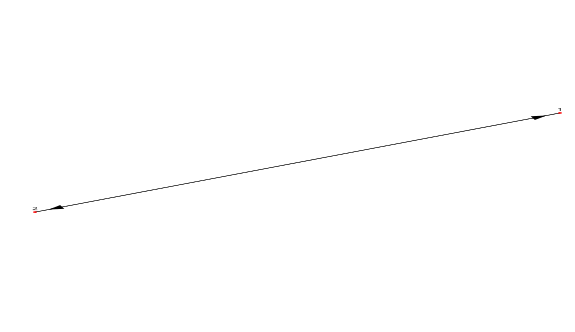

In [11]:
visualize(G)

In [10]:
Qg = quiver_grassmannian(Q,[2,2])

Quiver Grassmannian over Prime field of characteristic 3 with subspace dimensions [2, 2] defined by Ideal with 34 generators

In [93]:
Qg.quiver_representation

Quiver representation over Prime field of characteristic 3 with ambient dimensions [4, 4] and 2 arrows

In [59]:
Qg.ambient_ring

Multivariate polynomial ring in 12 variables over GF(3) graded by
  x[(1, [1, 2])] -> [1 0]
  x[(1, [1, 3])] -> [1 0]
  x[(1, [1, 4])] -> [1 0]
  x[(1, [2, 3])] -> [1 0]
  x[(1, [2, 4])] -> [1 0]
  x[(1, [3, 4])] -> [1 0]
  x[(2, [1, 2])] -> [0 1]
  x[(2, [1, 3])] -> [0 1]
  x[(2, [1, 4])] -> [0 1]
  x[(2, [2, 3])] -> [0 1]
  x[(2, [2, 4])] -> [0 1]
  x[(2, [3, 4])] -> [0 1]

In [60]:
Qg.defining_ideal

Ideal generated by
  2*x[(1, [1, 3])]*x[(2, [1, 4])] + x[(1, [1, 4])]*x[(2, [1, 3])]
  x[(1, [1, 2])]*x[(2, [3, 4])] + 2*x[(1, [1, 3])]*x[(2, [2, 4])] + x[(1, [1, 4])]*x[(2, [2, 3])]
  2*x[(1, [1, 2])]*x[(2, [1, 4])] + x[(1, [1, 4])]*x[(2, [1, 2])]
  2*x[(1, [1, 2])]*x[(2, [1, 3])] + x[(1, [1, 3])]*x[(2, [1, 2])]
  2*x[(1, [1, 2])]*x[(2, [3, 4])] + 2*x[(1, [2, 3])]*x[(2, [1, 4])] + x[(1, [2, 4])]*x[(2, [1, 3])]
  2*x[(1, [2, 3])]*x[(2, [2, 4])] + x[(1, [2, 4])]*x[(2, [2, 3])]
  2*x[(1, [1, 2])]*x[(2, [2, 4])] + x[(1, [2, 4])]*x[(2, [1, 2])]
  2*x[(1, [1, 2])]*x[(2, [2, 3])] + x[(1, [2, 3])]*x[(2, [1, 2])]
  2*x[(1, [1, 3])]*x[(2, [3, 4])] + x[(1, [3, 4])]*x[(2, [1, 3])]
  2*x[(1, [2, 3])]*x[(2, [3, 4])] + x[(1, [3, 4])]*x[(2, [2, 3])]
  2*x[(1, [1, 3])]*x[(2, [2, 4])] + x[(1, [2, 3])]*x[(2, [1, 4])] + x[(1, [3, 4])]*x[(2, [1, 2])]
  2*x[(1, [1, 3])]*x[(2, [2, 3])] + x[(1, [2, 3])]*x[(2, [1, 3])]
  2*x[(1, [1, 4])]*x[(2, [3, 4])] + x[(1, [3, 4])]*x[(2, [1, 4])]
  2*x[(1, [2, 4])]*x[(2, 

## **Example: Edge** MOVE TO TOP

Consider the quiver given by $$A:\mathbb{C}^{2}\longrightarrow\mathbb{C}^{4},$$ where 
$$A = \begin{bmatrix}1 &0 &0 &0 \\
0 &1 &0 &0\end{bmatrix}^{T}$$
and $d=(1,2)$

In [61]:
G = graph_from_edges(Directed,[[1,2]])
A = matrix(QQ,[1 0 0 0;0 1 0 0]);
Q = quiver_representation(G,[2,4],[A],QQ)

Quiver representation over Rational field with ambient dimensions [2, 4] and 1 arrows

In [62]:
Qsr = quiver_grassmannian(Q,[1,2])

Quiver Grassmannian over Rational field with subspace dimensions [1, 2] defined by Ideal with 5 generators

In [63]:
Qsr.defining_ideal

Ideal generated by
  -x[(1, [1])]*x[(2, [3, 4])]
  -x[(1, [2])]*x[(2, [3, 4])]
  -x[(1, [1])]*x[(2, [2, 4])] + x[(1, [2])]*x[(2, [1, 4])]
  -x[(1, [1])]*x[(2, [2, 3])] + x[(1, [2])]*x[(2, [1, 3])]
  x[(2, [1, 2])]*x[(2, [3, 4])] - x[(2, [1, 3])]*x[(2, [2, 4])] + x[(2, [1, 4])]*x[(2, [2, 3])]

## **Example from Iezzi-Schleis** LINK TO CITATION

In [64]:
ns = [4,4,4,4]

4-element Vector{Int64}:
 4
 4
 4
 4

In [65]:
dims = [1,2,2,3]

4-element Vector{Int64}:
 1
 2
 2
 3

In [66]:
GQ = graph_from_edges(Directed,[[1,2],[1,3],[2,4],[3,4]])

Directed graph with 4 nodes and the following edges:
(1, 2)(1, 3)(2, 4)(3, 4)

In [67]:
P, t = rational_function_field(QQ, :t)

(Rational function field over QQ, t)

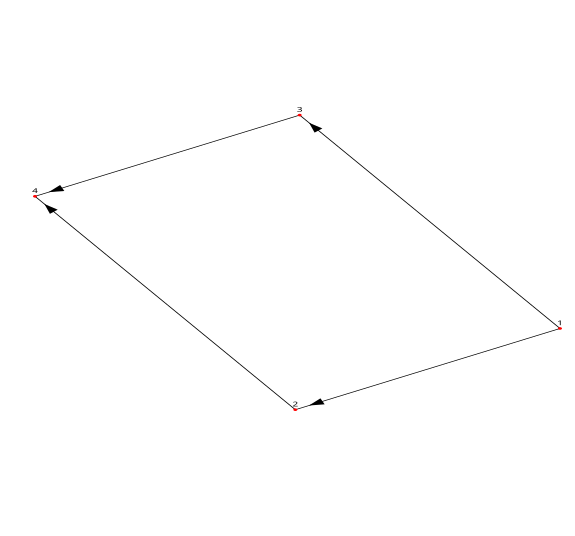

In [68]:
visualize(GQ)

In [69]:
Q = quiver_representation(GQ,ns,[identity_matrix(QQ,4) for i in 1:4],P)

Quiver representation over Rational function field over QQ with ambient dimensions [4, 4, 4, 4] and 4 arrows

In [70]:
Qrep = quiver_grassmannian(Q,dims)

Quiver Grassmannian over Rational function field over QQ with subspace dimensions [1, 2, 2, 3] defined by Ideal with 18 generators

In [71]:
Qrep.ambient_ring

Multivariate polynomial ring in 20 variables over P graded by
  x[(1, [1])] -> [1 0 0 0]
  x[(1, [2])] -> [1 0 0 0]
  x[(1, [3])] -> [1 0 0 0]
  x[(1, [4])] -> [1 0 0 0]
  x[(2, [1, 2])] -> [0 1 0 0]
  x[(2, [1, 3])] -> [0 1 0 0]
  x[(2, [1, 4])] -> [0 1 0 0]
  x[(2, [2, 3])] -> [0 1 0 0]
  x[(2, [2, 4])] -> [0 1 0 0]
  x[(2, [3, 4])] -> [0 1 0 0]
  x[(3, [1, 2])] -> [0 0 1 0]
  x[(3, [1, 3])] -> [0 0 1 0]
  x[(3, [1, 4])] -> [0 0 1 0]
  x[(3, [2, 3])] -> [0 0 1 0]
  x[(3, [2, 4])] -> [0 0 1 0]
  x[(3, [3, 4])] -> [0 0 1 0]
  x[(4, [1, 2, 3])] -> [0 0 0 1]
  x[(4, [1, 2, 4])] -> [0 0 0 1]
  x[(4, [1, 3, 4])] -> [0 0 0 1]
  x[(4, [2, 3, 4])] -> [0 0 0 1]

In [72]:
Qrep.defining_ideal

Ideal generated by
  -x[(1, [1])]*x[(2, [3, 4])] + x[(1, [3])]*x[(2, [1, 4])] - x[(1, [4])]*x[(2, [1, 3])]
  -x[(1, [2])]*x[(2, [3, 4])] + x[(1, [3])]*x[(2, [2, 4])] - x[(1, [4])]*x[(2, [2, 3])]
  -x[(1, [1])]*x[(2, [2, 4])] + x[(1, [2])]*x[(2, [1, 4])] - x[(1, [4])]*x[(2, [1, 2])]
  -x[(1, [1])]*x[(2, [2, 3])] + x[(1, [2])]*x[(2, [1, 3])] - x[(1, [3])]*x[(2, [1, 2])]
  -x[(1, [1])]*x[(3, [3, 4])] + x[(1, [3])]*x[(3, [1, 4])] - x[(1, [4])]*x[(3, [1, 3])]
  -x[(1, [2])]*x[(3, [3, 4])] + x[(1, [3])]*x[(3, [2, 4])] - x[(1, [4])]*x[(3, [2, 3])]
  -x[(1, [1])]*x[(3, [2, 4])] + x[(1, [2])]*x[(3, [1, 4])] - x[(1, [4])]*x[(3, [1, 2])]
  -x[(1, [1])]*x[(3, [2, 3])] + x[(1, [2])]*x[(3, [1, 3])] - x[(1, [3])]*x[(3, [1, 2])]
  -x[(2, [1, 2])]*x[(4, [1, 3, 4])] + x[(2, [1, 3])]*x[(4, [1, 2, 4])] - x[(2, [1, 4])]*x[(4, [1, 2, 3])]
  -x[(2, [1, 2])]*x[(4, [2, 3, 4])] + x[(2, [2, 3])]*x[(4, [1, 2, 4])] - x[(2, [2, 4])]*x[(4, [1, 2, 3])]
  -x[(2, [1, 3])]*x[(4, [2, 3, 4])] + x[(2, [2, 3])]*x[(4, [1, 3,

In [73]:
R = affine_scheme(Qrep.ambient_ring,Qrep.defining_ideal) 
dim(R)

11

## **Another example (Del Pezzo surface)**

In [74]:
Q = graph_from_edges(Directed,[[1,2],[3,2],[4,2]])

Directed graph with 4 nodes and the following edges:
(1, 2)(3, 2)(4, 2)

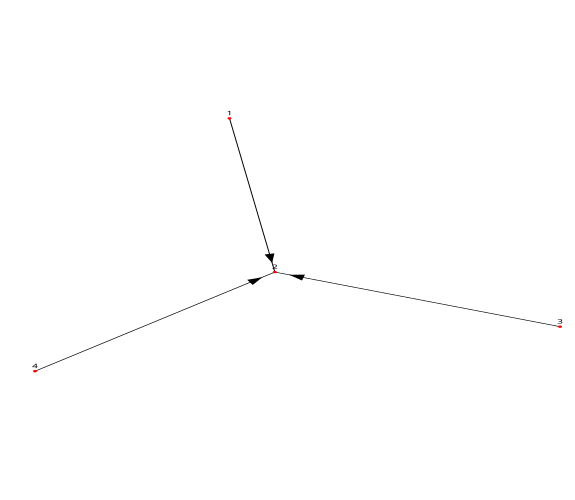

In [75]:
visualize(Q)

In [76]:
ns = [2,3,2,2]

4-element Vector{Int64}:
 2
 3
 2
 2

In [77]:
A1 = matrix(QQ,[1 0 0;0 1 0])

[1   0   0]
[0   1   0]

In [78]:
A2 = matrix(QQ,[0 1 0;0 0 1])

[0   1   0]
[0   0   1]

In [79]:
A3 = matrix(QQ,[1 0 0;0 0 1])

[1   0   0]
[0   0   1]

In [80]:
P, t = rational_function_field(QQ, :t)

(Rational function field over QQ, t)

In [81]:
QR = quiver_representation(Q,ns,[A1,A2,A3],QQ)

Quiver representation over Rational field with ambient dimensions [2, 3, 2, 2] and 3 arrows

In [82]:
e = [1,2,1,1]

4-element Vector{Int64}:
 1
 2
 1
 1

In [83]:
Qsub = quiver_grassmannian(QR,e)

Quiver Grassmannian over Rational field with subspace dimensions [1, 2, 1, 1] defined by Ideal with 3 generators